# Part II · Notebook 05 — X6 regulatory risk mapping, X7 gate validation, and verdicts on H6–H14

This notebook runs no new generator fits. It reads the result files of Part I and Notebooks 01–04, applies the
pre-specified rules of Notebook 00, maps every release to a regulatory risk tier, and checks the proposed acceptance
gates on the four datasets that were not used to set them.

In [1]:
import os, json, time, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import sdaudit as sa
OUT = "outputs2"; T = f"{OUT}/tables"
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1); plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
H = json.load(open(f"{T}/X0_hypotheses.json"))
X5 = pd.read_csv(f"{T}/X5_results.csv"); SH = pd.read_csv(f"{T}/X1_shadow.csv"); AUD = pd.read_csv(f"{T}/X1_dp_audit.csv")
REC = pd.read_csv(f"{T}/X2_reconstruction.csv"); TU = pd.read_csv(f"{T}/X3_tuning.csv"); X4 = pd.read_csv(f"{T}/X4_representation.csv")
P1 = pd.read_csv("partI/main_results.csv"); P1 = P1[P1.generator != "REAL (TRTR)"]
NEWDS = ["COMPAS", "Credit", "Bank", "Diabetes130"]; N5 = X5[X5.dataset.isin(NEWDS)]
SYN7 = sa.MAINSTREAM + ["MST (ε=1)"]
V = []
def verdict(h, v, ev): V.append(dict(ID=h, hypothesis=H[h], verdict=v, evidence=ev))

## H6–H8: stronger adversaries

In [2]:
p6 = stats.wilcoxon(SH.auc, SH.bb_auc, alternative="greater").pvalue
verdict("H6", "Supported" if p6 < 0.05 else "Not supported",
        f"Shadow-model AUC {SH.auc.mean():.3f} vs black-box {SH.bb_auc.mean():.3f} on the same releases (n={len(SH)} target x generator pairs; Wilcoxon p={p6:.2g}).")
vv, rr = SH[SH.kind == "vulnerable"].auc, SH[SH.kind == "random"].auc; p7 = stats.mannwhitneyu(vv, rr, alternative="greater").pvalue
verdict("H7", "Supported" if p7 < 0.05 else "Not supported", f"Vulnerable targets AUC {vv.mean():.3f} vs random {rr.mean():.3f} (Mann-Whitney p={p7:.2g}).")
mst = AUD[AUD.mechanism == "MST"]; cart = AUD[AUD.mechanism == "CART"].iloc[0]
ok8 = (mst.eps_lb <= mst.eps_nominal).all() and cart.eps_lb > mst[mst.eps_nominal == 1.0].eps_lb.iloc[0]
verdict("H8", "Supported" if ok8 else "Not supported",
        "MST empirical eps lower bounds: " + "; ".join(f"eps={e:g}: {b:.2f}" for e, b in zip(mst.eps_nominal, mst.eps_lb)) + f"; CART: {cart.eps_lb:.2f}.")
display(SH.groupby(["generator", "kind"])[["auc", "bb_auc"]].mean().round(3)); AUD.round(3)

auc  bb_auc
generator      kind                     
CART           random      0.599   0.656
               vulnerable  0.790   0.743
GaussianCopula random      0.477   0.476
               vulnerable  0.656   0.612
Independent    random      0.570   0.578
               vulnerable  0.629   0.530
TVAE           random      0.378   0.550
               vulnerable  0.493   0.546

,mechanism,eps_nominal,auc,bb_auc,threshold,eps_lb,eps_lb_best_threshold
0,MST,1.0,0.527,0.451,0.258,0.0,0.0
1,MST,10.0,0.454,0.535,0.182,0.0,0.0
2,MST,100.0,0.573,0.634,0.691,0.0,0.0
3,CART,inf,0.600,0.676,0.196,0.0,0.0


## H9: linear reconstruction

In [3]:
REC["advantage"] = REC.acc_mem - REC.acc_non
g9 = REC[REC.generator.isin(sa.MAINSTREAM)].groupby("generator").advantage.agg(["mean", sa.ci_t])
g9["p"] = [stats.wilcoxon(REC[REC.generator == g].advantage, alternative="greater").pvalue for g in g9.index]; g9["p_holm"] = sa.holm(g9.p)
sig9 = [g for g, r in g9.iterrows() if r["mean"] - r["ci_t"] > 0]
verdict("H9", "Supported" if len(sig9) > len(g9) / 2 else ("Partially supported" if sig9 else "Not supported"),
        f"Advantage CI > 0 for {len(sig9)}/{len(g9)} generators ({', '.join(sig9) or 'none'}); mean advantages: " + "; ".join(f"{g} {r['mean']:+.3f}" for g, r in g9.iterrows()) +
        f"; MST {REC[REC.generator=='MST (ε=1)'].advantage.mean():+.3f}.")
g9.round(4)

,mean,ci_t,p,p_holm
generator,,,,
AR-Transformer,0.0854,0.0245,0.0020,0.0117
CART,0.0372,0.0250,0.0020,0.0117
CTGAN,0.0039,0.0152,0.3379,1.0000
DDPM,0.0149,0.0123,0.0234,0.0938
GaussianCopula,0.0006,0.0175,0.6250,1.0000
TVAE,-0.0022,0.0251,0.6328,1.0000


## H10: tuning

In [4]:
rho10 = json.load(open(f"{T}/X3_rho.json")); r10 = rho10["rho_pair_mia"]
SEL = pd.read_csv(f"{T}/X3_fidelity_selection.csv")
verdict("H10", "Supported" if r10[1] > 0 else ("Contradicted" if r10[2] < 0 else "Not supported"),
        f"Pooled within-generator rho(pair, MIA AUC) = {r10[0]:.2f} [{r10[1]:.2f}, {r10[2]:.2f}]; outliers {rho10['rho_pair_outlier'][0]:.2f}. "
        f"Choosing the most faithful configuration changed MIA AUC by {SEL.d_mia.mean():+.3f} and TPR@1% by {SEL.d_tpr1.mean():+.3f} on average.")
SEL.groupby("generator")[["chosen", "default"]].agg(lambda x: ",".join(sorted(set(map(str, x)))))

,chosen,default
generator,,
AR-Transformer,750,1500
CART,1,5
CTGAN,600,300
DDPM,5000,5000
GaussianCopula,gaussian_kde,beta
TVAE,900,300


## H11–H12: representation repair

In [5]:
st = X4[X4.variant == "stratified"]; pl = X4[X4.variant == "plain"]
m = st.merge(pl, on=["dataset", "seed", "generator"], suffixes=("", "_pl"))
inband = st.repr_ratio.between(0.8, 1.25).mean(); du = (m.util_ratio - m.util_ratio_pl).mean()
verdict("H11", "Supported" if inband >= 0.9 and du >= -0.02 else "Not supported",
        f"Stratified release in band [0.8,1.25] in {inband:.0%} of runs (plain: {pl.repr_ratio.between(0.8,1.25).mean():.0%}); mean utility change {du:+.3f}; "
        f"max shortfall {int(st.shortfall.max())} records.")
pg = X4[X4.variant == "per-group"].merge(pl, on=["dataset", "seed", "generator"], suffixes=("", "_pl")).dropna(subset=["mia_auc_protected", "mia_auc_protected_pl"])
d12 = pg.mia_auc_protected - pg.mia_auc_protected_pl; p12 = stats.wilcoxon(d12, alternative="greater").pvalue
verdict("H12", "Supported" if p12 < 0.05 else "Not supported", f"Per-group generation changed protected-group MIA AUC by {d12.mean():+.3f} (Wilcoxon p={p12:.2g}, n={len(d12)}).")

## H13: replication on new datasets

In [6]:
tt = pd.read_csv(f"{T}/X5_mia_tests_new.csv"); leak = sorted(set(tt[tt.significant & tt.generator.isin(sa.MAINSTREAM)].generator))
rho13 = json.load(open(f"{T}/X5_rho_new.json"))["rho_util_mia"]
pooled = {g: sa.boot_ci(N5[N5.generator == g].util_ratio.values, groups=N5[N5.generator == g].dataset.values) for g in SYN7}
meet = [g for g in SYN7 if pooled[g][1] >= 0.90]
ok13 = len(leak) >= 4 and rho13[1] > 0 and len(meet) <= len(SYN7) / 2
verdict("H13", "Supported" if ok13 else "Partially supported",
        f"(a) {len(leak)}/6 mainstream generators leak significantly ({', '.join(leak)}); (b) rho(utility, MIA) = {rho13[0]:.2f} [{rho13[1]:.2f}, {rho13[2]:.2f}]; "
        f"(c) {len(meet)}/7 synthetic generators reach U >= 0.90 with CI ({', '.join(meet) or 'none'}).")
pd.DataFrame({g: dict(zip(["mean", "lo", "hi"], pooled[g])) for g in SYN7}).T.round(3)

,mean,lo,hi
GaussianCopula,0.892,0.877,0.907
CART,0.974,0.970,0.978
CTGAN,0.830,0.816,0.843
TVAE,0.935,0.921,0.951
DDPM,0.946,0.938,0.953
AR-Transformer,0.987,0.980,0.993
MST (ε=1),0.741,0.719,0.761


## X6: regulatory risk mapping
The GDPR treats data as anonymous only if identification is not "reasonably likely" (Recital 26). Attack results can be
turned into quantities a data-protection officer can reason about:
* **Exposed members per 10,000 released records** at a 1% false-positive rate: $10^4\,(\mathrm{TPR}_{1\%}-0.01)^+$;
* **Singled-out / linked individuals per 1,000 attempts**: $10^3 \times$ Anonymeter risk.

We then assign each release to a tier (our proposal, not legal advice):
**Tier 0 — no measurable risk:** TPR@1% ≤ 2× chance, outlier TPR@10% ≤ 2× chance, all Anonymeter 95% CIs include 0.
**Tier 1 — low but measurable:** TPR@1% ≤ 5× chance and all Anonymeter point estimates ≤ 0.05.
**Tier 2 — material:** everything else.

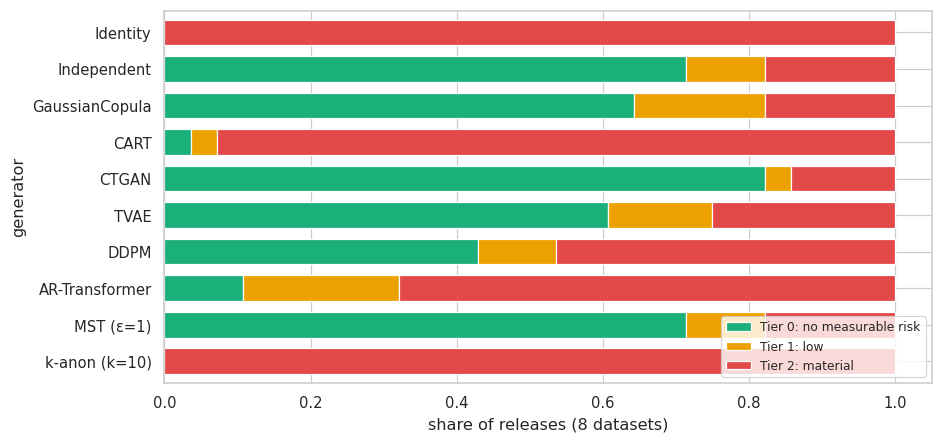

,runs,tier0,tier1,tier2,exposed_per_10k,singled_per_1k,linked_per_1k
generator,,,,,,,
Identity,28,0.000,0.000,1.000,7998.354,994.202,766.384
Independent,28,0.714,0.107,0.179,58.388,27.544,10.731
GaussianCopula,28,0.643,0.179,0.179,52.987,23.068,4.696
CART,28,0.036,0.036,0.929,253.124,97.007,120.267
CTGAN,28,0.821,0.036,0.143,41.295,17.829,8.460
TVAE,28,0.607,0.143,0.250,60.197,21.108,18.523
DDPM,28,0.429,0.107,0.464,332.822,46.109,110.355
AR-Transformer,28,0.107,0.214,0.679,2009.985,110.210,231.370
MST (ε=1),28,0.714,0.107,0.179,61.997,17.250,6.285


In [7]:
def tier(r):
    anon_lo = [r.get(f"anon_{k}_lo", 0) for k in ("singling", "link", "infer")]; anon = [r.get(f"anon_{k}", 0) for k in ("singling", "link", "infer")]
    out_ok = r.get("mia_tpr10_outlier", 0) <= 0.20 if pd.notna(r.get("mia_tpr10_outlier", np.nan)) else True
    if r["mia_tpr1_max"] <= 0.02 and out_ok and all((x or 0) <= 0 for x in anon_lo): return 0
    if r["mia_tpr1_max"] <= 0.05 and all((x or 0) <= 0.05 for x in anon): return 1
    return 2
ALL = pd.concat([P1.assign(source="Part I"), X5.assign(source="Part II")], ignore_index=True)
ALL = ALL[~((ALL.source == "Part II") & ALL.dataset.isin(["Adult", "German", "Fraud", "Pima"]) & (ALL.generator != "AR-Transformer"))]
ALL["tier"] = ALL.apply(tier, axis=1); ALL["exposed_per_10k"] = 1e4 * (ALL.mia_tpr1_max - 0.01).clip(lower=0)
ALL["singled_per_1k"] = 1e3 * ALL.anon_singling.clip(lower=0); ALL["linked_per_1k"] = 1e3 * ALL.anon_link.clip(lower=0)
reg = ALL.groupby("generator").agg(runs=("tier", "size"), tier0=("tier", lambda x: (x == 0).mean()), tier1=("tier", lambda x: (x == 1).mean()),
      tier2=("tier", lambda x: (x == 2).mean()), exposed_per_10k=("exposed_per_10k", "mean"), singled_per_1k=("singled_per_1k", "mean"),
      linked_per_1k=("linked_per_1k", "mean")).reindex(list(sa.GENERATORS))
reg.to_csv(f"{T}/X6_regulatory_tiers.csv"); ALL[["source", "dataset", "seed", "generator", "tier", "exposed_per_10k", "singled_per_1k", "linked_per_1k"]].to_csv(f"{T}/X6_tiers_long.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4.4))
reg[["tier0", "tier1", "tier2"]].plot.barh(stacked=True, ax=ax, color=["#1baf7a", "#eda100", "#e34948"], width=0.7)
ax.set_xlabel("share of releases (8 datasets)"); ax.legend(["Tier 0: no measurable risk", "Tier 1: low", "Tier 2: material"], loc="lower right", fontsize=8)
ax.invert_yaxis(); fig.savefig(f"{OUT}/figures/X6_tiers.png"); plt.show()
reg.round(3)

## X7 / H14: do the proposed gates work on data they were not calibrated on?

In [8]:
G5 = N5[~N5.generator.isin(["Identity"])].copy()
sens = {m_["name"]: list(m_["sensitive"]) for m_ in [sa.load(k)[1] for k in ["compas", "credit", "bank", "diabetes"]]}
og = G5.apply(lambda r: pd.Series(sa.original_gates(r, sens[r.dataset])), axis=1); pgt = G5.apply(lambda r: pd.Series(sa.proposed_gates(r, sens[r.dataset])), axis=1)
G5 = pd.concat([G5, og, pgt], axis=1)
G5["ok_original"] = G5[["g_fidelity", "g_privacy", "g_utility", "g_diversity", "g_fairness"]].all(axis=1)
G5["ok_proposed"] = G5[["p_attack", "p_anonymeter", "p_representation", "p_outcome_gap", "p_utility"]].all(axis=1)
def repr_bad(r):
    xs = [r[f"{a}|share"] / r[f"{a}|share_real"] for a in sens[r.dataset]]; return any((x < 0.5 or x > 2) for x in xs)
G5["harm_repr"] = G5.apply(repr_bad, axis=1); G5["harm_attack"] = G5.mia_tpr1_max >= 0.05; G5["harm"] = G5.harm_repr | G5.harm_attack
att = G5[G5.generator.isin(SYN7 + ["Independent"])].groupby("dataset").ok_proposed.any()
missed = G5[G5.ok_original & G5.harm]
verdict("H14", "Supported" if att.sum() >= 3 and len(missed) > 0 else ("Partially supported" if att.sum() >= 3 or len(missed) > 0 else "Not supported"),
        f"(a) proposed gates attainable on {int(att.sum())}/4 new datasets ({', '.join(att[att].index)}); (b) original gates approved {len(missed)} harmful release(s)"
        + (f": " + "; ".join(f"{r.dataset} {r.generator} s{r.seed}" for _, r in missed.iterrows()) if len(missed) else "") + ".")
gate_tab = G5.groupby("generator")[["ok_original", "ok_proposed", "p_attack", "p_anonymeter", "p_representation", "p_outcome_gap", "p_utility", "harm"]].mean().reindex([g for g in sa.GENERATORS if g != "Identity"])
gate_tab.to_csv(f"{T}/X7_gates_new_datasets.csv"); G5.to_csv(f"{T}/X7_gates_long.csv", index=False)
gate_tab.round(2)

,ok_original,ok_proposed,p_attack,p_anonymeter,p_representation,p_outcome_gap,p_utility,harm
generator,,,,,,,,
Independent,0.00,0.00,1.00,0.83,0.92,0.25,0.00,0.00
GaussianCopula,0.00,0.17,1.00,0.83,0.75,0.25,0.42,0.00
CART,0.00,0.00,0.00,0.00,0.92,0.83,1.00,0.00
CTGAN,0.00,0.00,0.92,0.92,0.08,0.00,0.00,0.17
TVAE,0.00,0.00,0.92,0.58,0.00,0.33,0.83,0.75
DDPM,0.08,0.17,1.00,0.75,0.50,0.42,0.75,0.50
AR-Transformer,0.08,0.00,0.17,0.33,1.00,0.75,1.00,0.00
MST (ε=1),0.00,0.00,1.00,0.92,0.83,0.00,0.25,0.00
k-anon (k=10),0.00,0.00,0.00,0.00,0.92,0.75,1.00,0.75


## Verdicts on H6–H14

In [9]:
VV = pd.DataFrame(V); VV.to_csv(f"{T}/X_verdicts.csv", index=False)
VV.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

ID,hypothesis,verdict,evidence
H6,"X1: record-targeted shadow-model attacks are stronger than the black-box distance attack on the same targets (paired Wilcoxon over target x generator, one-sided, alpha=0.05).",Not supported,Shadow-model AUC 0.598 vs black-box 0.593 on the same releases (n=34 target x generator pairs; Wilcoxon p=0.39).
H7,"X1: the most vulnerable records are more exposed than random records (shadow-attack AUC; one-sided Mann-Whitney pooled over generators, alpha=0.05).",Supported,Vulnerable targets AUC 0.668 vs random 0.528 (Mann-Whitney p=0.0036).
H8,X1: MST's empirical epsilon lower bound never exceeds its nominal epsilon (implementation consistent); the non-DP CART bound on the same target exceeds MST(eps=1)'s.,Not supported,MST empirical eps lower bounds: eps=1: 0.00; eps=10: 0.00; eps=100: 0.00; CART: 0.00.
H9,"X2: for non-DP generators, linear reconstruction recovers members' secrets more accurately than non-members' (advantage > 0 with 95% CI excluding 0) for most generators.",Partially supported,"Advantage CI > 0 for 3/6 generators (AR-Transformer, CART, DDPM); mean advantages: AR-Transformer +0.085; CART +0.037; CTGAN +0.004; DDPM +0.015; GaussianCopula +0.001; TVAE -0.002; MST +0.009."
H10,"X3: tuning for fidelity increases leakage: pooled within-generator Spearman rho(pair fidelity, MIA AUC) across configurations > 0 with CI excluding 0.",Supported,"Pooled within-generator rho(pair, MIA AUC) = 0.48 [0.28, 0.65]; outliers 0.36. Choosing the most faithful configuration changed MIA AUC by +0.035 and TPR@1% by +0.026 on average."
H11,"X4: stratified release brings the protected-group share ratio into [0.8, 1.25] in >= 90% of runs, with a mean utility change >= -0.02.",Supported,"Stratified release in band [0.8,1.25] in 100% of runs (plain: 47%); mean utility change +0.002; max shortfall 91 records."
H12,"X4: per-group generation increases membership risk for protected-group records (protected-target MIA AUC higher than under plain generation; paired Wilcoxon, alpha=0.05).",Not supported,"Per-group generation changed protected-group MIA AUC by +0.006 (Wilcoxon p=0.15, n=36)."
H13,"X5: Part I replicates on four new datasets: (a) >= 4 of 6 mainstream generators leak significantly (Holm), (b) rho(utility, MIA AUC) > 0 with CI excluding 0, (c) at most half of the synthetic generators reach U >= 0.90 with CI.",Partially supported,"(a) 3/6 mainstream generators leak significantly (AR-Transformer, CART, DDPM); (b) rho(utility, MIA) = 0.57 [0.41, 0.70]; (c) 4/7 synthetic generators reach U >= 0.90 with CI (CART, TVAE, DDPM, AR-Transformer)."
H14,"X7: on the four new datasets (not used to set the thresholds), (a) the proposed gates are attainable: at least one synthetic mechanism passes on >= 3 of 4 datasets; (b) the original gates approve at least one release that has a representation ratio outside [0.5, 2] or an attack TPR@1% >= 5x chance. (The proposed gates reject such runs by construction, so (b) is the informative comparison.)",Not supported,"(a) proposed gates attainable on 2/4 new datasets (COMPAS, Diabetes130); (b) original gates approved 0 harmful release(s)."
